In [ ]:
print("Hello! My CSE 445 project has started.")

Hello! My CSE 445 project has started.


Original image size: (100, 100)
Enlarged image size: (200, 200)


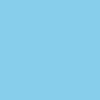

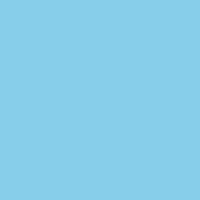

In [ ]:
from PIL import Image
from IPython.display import display

# Create a sample image
image = Image.new("RGB", (100, 100), "skyblue")

# Enlarge the image using bicubic interpolation
enlarged = image.resize(
    (200, 200),
    Image.Resampling.BICUBIC
)

print("Original image size:", image.size)
print("Enlarged image size:", enlarged.size)

display(image)
display(enlarged)

In [10]:
import zipfile
import os
from PIL import Image
from google.colab import files

# Upload dataset ZIP
uploaded = files.upload()

zip_filename = next(iter(uploaded))

# Extract ZIP
extract_path = "/content/Dataset_1"

with zipfile.ZipFile(zip_filename, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

# Find image files
image_extensions = ('.jpg', '.jpeg', '.png', '.bmp')

image_files = []

for root, dirs, filenames in os.walk(extract_path):
    for filename in filenames:
        if filename.lower().endswith(image_extensions):
            image_files.append(os.path.join(root, filename))

print("Total images found:", len(image_files))

# Open first image
original = Image.open(image_files[0]).convert("RGB")
small = original.resize(
    (original.width // 2, original.height // 2),
    Image.Resampling.BICUBIC
)

bicubic = small.resize(
    original.size,
    Image.Resampling.BICUBIC
)

print("Original image size:", original.size)

Saving Dataset_1.zip to Dataset_1.zip
Dataset extracted successfully!
Total images found: 100
Original image size: (425, 640)


In [ ]:
import os

os.makedirs("outputs", exist_ok=True)

original.save("outputs/original.png")
small.save("outputs/low_resolution.png")
bicubic.save("outputs/bicubic.png")

print("All three images saved successfully!")

All three images saved successfully!


In [ ]:
import os
import shutil

source = "/content/Dataset_1"
destination = "/content/dataset/images"

os.makedirs(destination, exist_ok=True)

shutil.copytree(
    os.path.join(source, "High res"),
    os.path.join(destination, "High res"),
    dirs_exist_ok=True
)

shutil.copytree(
    os.path.join(source, "Low res"),
    os.path.join(destination, "Low res"),
    dirs_exist_ok=True
)

print("Dataset folders prepared successfully!")
print("HR images:", len(os.listdir(destination + "/High res")))
print("LR images:", len(os.listdir(destination + "/Low res")))

Dataset folders prepared successfully!
HR images: 50
LR images: 50


In [ ]:
import numpy as np
from skimage.metrics import peak_signal_noise_ratio
from skimage.metrics import structural_similarity

# Convert images to NumPy arrays
original_array = np.array(original)
bicubic_array = np.array(bicubic)

# Calculate PSNR
psnr_value = peak_signal_noise_ratio(
    original_array,
    bicubic_array,
    data_range=255
)

# Calculate SSIM
ssim_value = structural_similarity(
    original_array,
    bicubic_array,
    channel_axis=2,
    data_range=255
)

print("Bicubic PSNR:", round(psnr_value, 2), "dB")
print("Bicubic SSIM:", round(ssim_value, 4))


Bicubic PSNR: 31.59 dB
Bicubic SSIM: 0.9262


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving deep-learning-image-enhancer-Meheraj.zip to deep-learning-image-enhancer-Meheraj (1).zip


In [ ]:
from google.colab import files

uploaded = files.upload()

print("Uploaded file names:")
print(list(uploaded.keys()))

Saving deep-learning-image-enhancer-Meheraj.zip to deep-learning-image-enhancer-Meheraj (2).zip
Uploaded file names:
['deep-learning-image-enhancer-Meheraj (2).zip']


In [ ]:
import os
import zipfile

zip_files = [
    name for name in uploaded.keys()
    if name.lower().endswith(".zip")
]

if not zip_files:
    print("ERROR: No ZIP file uploaded. Please upload Dataset_1.zip.")
else:
    zip_path = zip_files[0]
    extract_path = "/content/dataset"

    os.makedirs(extract_path, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(extract_path)

    print("Dataset extracted successfully!")
    print("Items inside dataset:")

    for item in os.listdir(extract_path):
        print("-", item)

Dataset extracted successfully!
Items inside dataset:
- deep-learning-image-enhancer-Meheraj


In [ ]:
import os

dataset_path = "/content/dataset"

total_images = 0
image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

print("Dataset folder contents:\n")

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        if file.lower().endswith(image_extensions):
            total_images += 1
            if total_images <= 10:
                print(f"{indent}  {file}")

print("\nTotal image files:", total_images)

Dataset folder contents:

dataset/
  deep-learning-image-enhancer-Meheraj/

Total image files: 0


In [ ]:
import os

dataset_path = "/content/dataset"

for root, dirs, files in os.walk(dataset_path):
    print("\nFolder:", root)
    print("Subfolders:", dirs)
    print("Files:", files[:20])


Folder: /content/dataset
Subfolders: ['deep-learning-image-enhancer-Meheraj']
Files: []

Folder: /content/dataset/deep-learning-image-enhancer-Meheraj
Subfolders: []
Files: ['Dataset_1.zip', 'README.md']


In [ ]:
import os
import zipfile

inner_zip = "/content/dataset/deep-learning-image-enhancer-Meheraj/Dataset_1.zip"
extract_path = "/content/dataset/images"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(inner_zip, "r") as z:
    z.extractall(extract_path)

print("Dataset_1.zip extracted successfully!")

for root, dirs, files in os.walk(extract_path):
    print("\nFolder:", root)
    print("Subfolders:", dirs)
    print("Number of files:", len(files))
    print("Sample files:", files[:10])

Dataset_1.zip extracted successfully!

Folder: /content/dataset/images
Subfolders: ['High res', 'Low res', '__MACOSX']
Number of files: 0
Sample files: []

Folder: /content/dataset/images/High res
Subfolders: []
Number of files: 50
Sample files: ['000000002685.jpg', '000000001503.jpg', '000000000139.jpg', '000000002532.jpg', '000000002473.jpg', '000000003156.jpg', '000000000724.jpg', '000000001818.jpg', '000000002592.jpg', '000000001993.jpg']

Folder: /content/dataset/images/Low res
Subfolders: []
Number of files: 50
Sample files: ['000000002685.jpg', '000000001503.jpg', '000000000139.jpg', '000000002532.jpg', '000000002473.jpg', '000000003156.jpg', '000000000724.jpg', '000000001818.jpg', '000000002592.jpg', '000000001993.jpg']

Folder: /content/dataset/images/__MACOSX
Subfolders: ['High res', 'Low res']
Number of files: 0
Sample files: []

Folder: /content/dataset/images/__MACOSX/High res
Subfolders: []
Number of files: 50
Sample files: ['._000000001675.jpg', '._000000001532.jpg', '._

In [ ]:
import os
from PIL import Image

hr_path = "/content/dataset/images/High res"
lr_path = "/content/dataset/images/Low res"

valid_ext = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

hr_files = {
    f for f in os.listdir(hr_path)
    if f.lower().endswith(valid_ext)
}
lr_files = {
    f for f in os.listdir(lr_path)
    if f.lower().endswith(valid_ext)
}

matched = sorted(hr_files & lr_files)

print("High-resolution images:", len(hr_files))
print("Low-resolution images:", len(lr_files))
print("Matching image pairs:", len(matched))
print("\nFirst 5 image pairs:")

for name in matched[:5]:
    with Image.open(os.path.join(hr_path, name)) as hr:
        hr_size = hr.size
    with Image.open(os.path.join(lr_path, name)) as lr:
        lr_size = lr.size

    print(f"{name}: HR={hr_size}, LR={lr_size}")

High-resolution images: 50
Low-resolution images: 50
Matching image pairs: 50

First 5 image pairs:
000000000139.jpg: HR=(640, 426), LR=(640, 426)
000000000285.jpg: HR=(586, 640), LR=(586, 640)
000000000632.jpg: HR=(640, 483), LR=(640, 483)
000000000724.jpg: HR=(375, 500), LR=(375, 500)
000000000776.jpg: HR=(428, 640), LR=(428, 640)


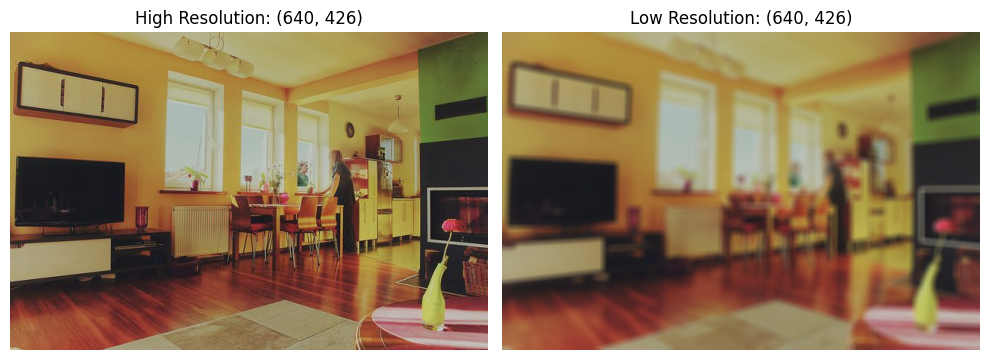

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import os

hr_path = "/content/dataset/images/High res"
lr_path = "/content/dataset/images/Low res"

filename = "000000000139.jpg"

hr = Image.open(os.path.join(hr_path, filename))
lr = Image.open(os.path.join(lr_path, filename))

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(hr)
plt.title(f"High Resolution: {hr.size}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(lr)
plt.title(f"Low Resolution: {lr.size}")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os
from PIL import Image

hr_path = "/content/dataset/images/High res"
lr_path = "/content/dataset/images/Low res"

image_names = sorted(
    f for f in os.listdir(hr_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
)

valid_pairs = 0
invalid_pairs = []

for name in image_names:
    hr_file = os.path.join(hr_path, name)
    lr_file = os.path.join(lr_path, name)

    if not os.path.exists(lr_file):
        invalid_pairs.append(name)
        continue

    with Image.open(hr_file) as hr, Image.open(lr_file) as lr:
        if hr.size == lr.size:
            valid_pairs += 1
        else:
            invalid_pairs.append(name)

print("Same-size image pairs:", valid_pairs)
print("Pairs needing inspection:", len(invalid_pairs))
print("Dataset check completed.")

Same-size image pairs: 50
Pairs needing inspection: 0
Dataset check completed.


In [ ]:
from PIL import Image
import os

hr_path = "/content/dataset/images/High res"
lr_path = "/content/dataset/images/Low res"

filename = "000000000139.jpg"

hr = Image.open(os.path.join(hr_path, filename))
lr = Image.open(os.path.join(lr_path, filename))

print("HR size:", hr.size)
print("LR size:", lr.size)
print("HR image mode:", hr.mode)
print("LR image mode:", lr.mode)
print("HR file size (KB):",
      round(os.path.getsize(os.path.join(hr_path, filename)) / 1024, 2))
print("LR file size (KB):",
      round(os.path.getsize(os.path.join(lr_path, filename)) / 1024, 2))

HR size: (640, 426)
LR size: (640, 426)
HR image mode: RGB
LR image mode: RGB
HR file size (KB): 43.3
LR file size (KB): 46.96


In [ ]:
readme_path = (
    "/content/dataset/"
    "deep-learning-image-enhancer-Meheraj/README.md"
)

with open(readme_path, "r", encoding="utf-8") as file:
    print(file.read())

# deep-learning-image-enhancer
A Machine Learning project focused on enhancing low-resolution images using a deep learning-based super-resolution model (SRCNN). The project compares the model's performance with bicubic interpolation using PSNR and SSIM metrics.



In [ ]:
from PIL import Image
import numpy as np
import os

hr_path = "/content/dataset/images/High res/000000000139.jpg"
lr_path = "/content/dataset/images/Low res/000000000139.jpg"

hr = np.array(Image.open(hr_path).convert("RGB")).astype(np.float32)
lr = np.array(Image.open(lr_path).convert("RGB")).astype(np.float32)

print("HR shape:", hr.shape)
print("LR shape:", lr.shape)
print("Images exactly identical:", np.array_equal(hr, lr))
print("Mean absolute pixel difference:", np.mean(np.abs(hr - lr)))

HR shape: (426, 640, 3)
LR shape: (426, 640, 3)
Images exactly identical: False
Mean absolute pixel difference: 8.4836035


In [ ]:
import os
import numpy as np
from PIL import Image

hr_path = "/content/dataset/images/High res"
output_path = "/content/srcnn_dataset"

os.makedirs(output_path, exist_ok=True)
os.makedirs(f"{output_path}/LR", exist_ok=True)
os.makedirs(f"{output_path}/HR", exist_ok=True)

image_extensions = (".jpg", ".jpeg", ".png")
image_names = sorted(
    f for f in os.listdir(hr_path)
    if f.lower().endswith(image_extensions)
)

successful = 0

for name in image_names:
    try:
        with Image.open(os.path.join(hr_path, name)) as img:
            hr = img.convert("RGB")

        width, height = hr.size

        # Make image dimensions even numbers so they can be halved
        new_width = width - (width % 2)
        new_height = height - (height % 2)
        hr = hr.crop((0, 0, new_width, new_height))

        # Create half-sized images
        small = hr.resize(
            (new_width // 2, new_height // 2),
            Image.Resampling.BICUBIC
        )

        # Resize the images back to HR dimensions using Bicubic interpolation
        lr = small.resize(
            (new_width, new_height),
            Image.Resampling.BICUBIC
        )

        hr.save(f"{output_path}/HR/{name}")
        lr.save(f"{output_path}/LR/{name}")

        successful += 1

    except Exception as e:
        print("Could not process:", name, "|", e)

print("Successfully processed:", successful)
print("HR training targets:", len(os.listdir(f"{output_path}/HR")))
print("LR training inputs:", len(os.listdir(f"{output_path}/LR")))


Successfully processed: 50
HR training targets: 50
LR training inputs: 50


In [ ]:
import os
import random
import numpy as np
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# 1. Reproducibility and device
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)

# 2. Dataset paths
lr_dir = "/content/srcnn_dataset/LR"
hr_dir = "/content/srcnn_dataset/HR"
model_path = "/content/srcnn_model.pth"

names = sorted(
    f for f in os.listdir(hr_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
    and os.path.exists(os.path.join(lr_dir, f))
)

random.shuffle(names)
split = max(1, int(len(names) * 0.8))
train_names = names[:split]
val_names = names[split:]

print("Training pairs:", len(train_names))
print("Validation pairs:", len(val_names))

# 3. Dataset with 64x64 image patches
class SRDataset(Dataset):
    def __init__(self, filenames, random_crop):
        self.filenames = filenames
        self.random_crop = random_crop
        self.patch_size = 64

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, idx):
        name = self.filenames[idx]

        lr = Image.open(os.path.join(lr_dir, name)).convert("RGB")
        hr = Image.open(os.path.join(hr_dir, name)).convert("RGB")

        # Ensure matching dimensions
        if lr.size != hr.size:
            raise ValueError(f"Image size mismatch: {name}")

        w, h = hr.size
        p = self.patch_size

        if w < p or h < p:
            raise ValueError(f"Image too small for a {p}x{p} patch: {name}")

        if self.random_crop:
            left = random.randint(0, w - p)
            top = random.randint(0, h - p)
        else:
            left = (w - p) // 2
            top = (h - p) // 2

        box = (left, top, left + p, top + p)
        lr = np.asarray(lr.crop(box), dtype=np.float32) / 255.0
        hr = np.asarray(hr.crop(box), dtype=np.float32) / 255.0

        # Convert HWC to CHW
        lr = torch.from_numpy(lr).permute(2, 0, 1)
        hr = torch.from_numpy(hr).permute(2, 0, 1)

        return lr, hr

train_ds = SRDataset(train_names, random_crop=True)
val_ds = SRDataset(val_names, random_crop=False)

train_loader = DataLoader(
    train_ds, batch_size=8, shuffle=True, num_workers=0
)
val_loader = DataLoader(
    val_ds, batch_size=1, shuffle=False, num_workers=0
)

# 4. SRCNN architecture
class SRCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=9, padding=4),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 32, kernel_size=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 3, kernel_size=5, padding=2)
        )

    def forward(self, x):
        return self.network(x)

model = SRCNN().to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# 5. Train the model
epochs = 30
best_val_loss = float("inf")

for epoch in range(epochs):
    model.train()
    train_loss = 0.0

    for lr, hr in train_loader:
        lr = lr.to(device)
        hr = hr.to(device)

        optimizer.zero_grad()
        output = model(lr)
        loss = criterion(output, hr)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * lr.size(0)

    train_loss /= len(train_ds)

    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for lr, hr in val_loader:
            lr = lr.to(device)
            hr = hr.to(device)
            output = model(lr)
            val_loss += criterion(output, hr).item()

    val_loss /= max(1, len(val_ds))

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), model_path)

    print(
        f"Epoch [{epoch+1:02d}/{epochs}] "
        f"Train Loss: {train_loss:.6f} | "
        f"Validation Loss: {val_loss:.6f}"
    )

print("\nTraining complete!")
print("Best validation loss:", round(best_val_loss, 6))
print("Saved model:", model_path)

Training device: cuda
Training pairs: 40
Validation pairs: 10
Epoch [01/30] Train Loss: 0.203939 | Validation Loss: 0.048173
Epoch [02/30] Train Loss: 0.063432 | Validation Loss: 0.033470
Epoch [03/30] Train Loss: 0.039180 | Validation Loss: 0.044832
Epoch [04/30] Train Loss: 0.036334 | Validation Loss: 0.027137
Epoch [05/30] Train Loss: 0.034601 | Validation Loss: 0.030137
Epoch [06/30] Train Loss: 0.022554 | Validation Loss: 0.027717
Epoch [07/30] Train Loss: 0.026116 | Validation Loss: 0.025363
Epoch [08/30] Train Loss: 0.024766 | Validation Loss: 0.023398
Epoch [09/30] Train Loss: 0.021581 | Validation Loss: 0.024061
Epoch [10/30] Train Loss: 0.020954 | Validation Loss: 0.022364
Epoch [11/30] Train Loss: 0.022082 | Validation Loss: 0.019895
Epoch [12/30] Train Loss: 0.016363 | Validation Loss: 0.017049
Epoch [13/30] Train Loss: 0.015372 | Validation Loss: 0.014692
Epoch [14/30] Train Loss: 0.015076 | Validation Loss: 0.013207
Epoch [15/30] Train Loss: 0.015814 | Validation Loss: 0.

Average results on 10 validation images
----------------------------------------
Bicubic PSNR: 27.2226 dB
SRCNN PSNR:   24.1740 dB
Bicubic SSIM: 0.8006
SRCNN SSIM:   0.7168

SRCNN - Bicubic improvement
PSNR change: -3.0486 dB
SSIM change: -0.0838


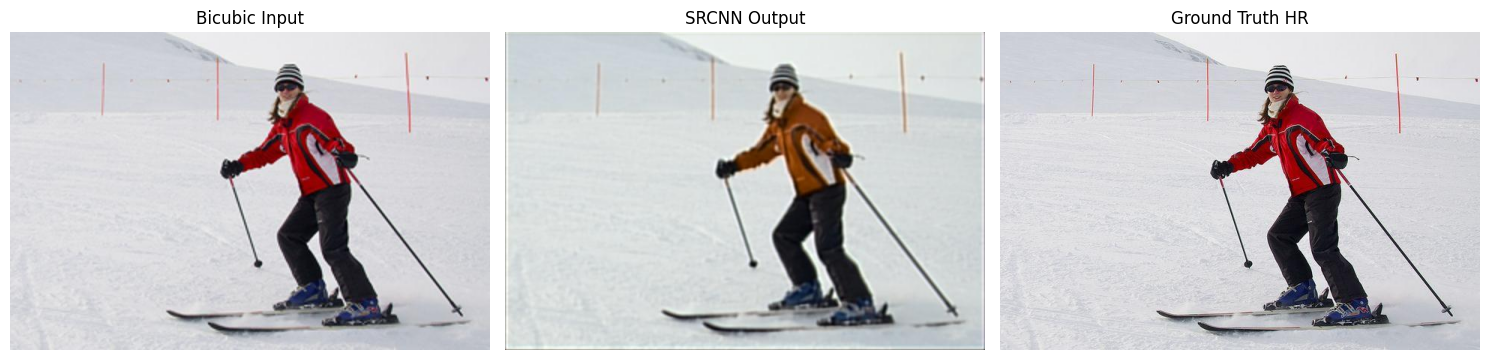


Output images saved to: /content/srcnn_outputs


In [ ]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt

from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

hr_dir = "/content/srcnn_dataset/HR"
lr_dir = "/content/srcnn_dataset/LR"
model_path = "/content/srcnn_model.pth"
output_dir = "/content/srcnn_outputs"

os.makedirs(output_dir, exist_ok=True)

# Load the saved SRCNN model
model = SRCNN().to(device)
model.load_state_dict(torch.load(model_path, map_location=device))
model.eval()

psnr_bicubic = []
ssim_bicubic = []
psnr_srcnn = []
ssim_srcnn = []

# Evaluate on the same 10 validation images
for name in val_names:
    hr = np.array(
        Image.open(os.path.join(hr_dir, name)).convert("RGB")
    )
    lr = np.array(
        Image.open(os.path.join(lr_dir, name)).convert("RGB")
    )

    # Convert LR image to tensor
    lr_tensor = torch.from_numpy(
        lr.astype(np.float32) / 255.0
    ).permute(2, 0, 1).unsqueeze(0).to(device)

    with torch.no_grad():
        pred = model(lr_tensor).squeeze(0).cpu().permute(1, 2, 0).numpy()

    # Convert model output to image range
    pred = np.clip(pred, 0, 1)
    pred_uint8 = (pred * 255).round().astype(np.uint8)

    # Calculate metrics against the HR target
    psnr_bicubic.append(
        peak_signal_noise_ratio(hr, lr, data_range=255)
    )
    ssim_bicubic.append(
        structural_similarity(
            hr, lr, channel_axis=2, data_range=255
        )
    )

    psnr_srcnn.append(
        peak_signal_noise_ratio(hr, pred_uint8, data_range=255)
    )
    ssim_srcnn.append(
        structural_similarity(
            hr, pred_uint8, channel_axis=2, data_range=255
        )
    )

    # Save one example of the model output
    Image.fromarray(pred_uint8).save(
        os.path.join(output_dir, name)
    )

print("Average results on 10 validation images")
print("----------------------------------------")
print(f"Bicubic PSNR: {np.mean(psnr_bicubic):.4f} dB")
print(f"SRCNN PSNR:   {np.mean(psnr_srcnn):.4f} dB")
print(f"Bicubic SSIM: {np.mean(ssim_bicubic):.4f}")
print(f"SRCNN SSIM:   {np.mean(ssim_srcnn):.4f}")

print("\nSRCNN - Bicubic improvement")
print(f"PSNR change: {np.mean(psnr_srcnn) - np.mean(psnr_bicubic):.4f} dB")
print(f"SSIM change: {np.mean(ssim_srcnn) - np.mean(ssim_bicubic):.4f}")

# Display one validation example
example_name = val_names[0]
hr_img = np.array(Image.open(os.path.join(hr_dir, example_name)).convert("RGB"))
lr_img = np.array(Image.open(os.path.join(lr_dir, example_name)).convert("RGB"))
srcnn_img = np.array(Image.open(os.path.join(output_dir, example_name)).convert("RGB"))

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(lr_img)
plt.title("Bicubic Input")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(srcnn_img)
plt.title("SRCNN Output")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(hr_img)
plt.title("Ground Truth HR")
plt.axis("off")

plt.tight_layout()
plt.show()

print("\nOutput images saved to:", output_dir)

In [ ]:
print("Model available:", model is not None)
print("Training samples:", len(train_ds))
print("Validation samples:", len(val_ds))
print("Saved model exists:", os.path.exists(model_path))

Model available: True
Training samples: 40
Validation samples: 10
Saved model exists: True


In [ ]:
# Continue training from the best saved model
model = SRCNN().to(device)
model.load_state_dict(torch.load(model_path, map_location=device))

# Use a smaller learning rate for fine-tuning
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
criterion = nn.MSELoss()

best_val_loss = float("inf")
fine_tune_epochs = 30

for epoch in range(fine_tune_epochs):
    model.train()
    train_loss = 0.0

    for lr, hr in train_loader:
        lr = lr.to(device)
        hr = hr.to(device)

        optimizer.zero_grad()
        output = model(lr)
        loss = criterion(output, hr)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * lr.size(0)

    train_loss /= len(train_ds)

    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for lr, hr in val_loader:
            lr = lr.to(device)
            hr = hr.to(device)
            output = model(lr)
            val_loss += criterion(output, hr).item()

    val_loss /= max(1, len(val_ds))

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "/content/srcnn_model_finetuned.pth")

    print(
        f"Fine-tune Epoch [{epoch+1:02d}/{fine_tune_epochs}] "
        f"Train Loss: {train_loss:.6f} | "
        f"Validation Loss: {val_loss:.6f}"
    )

print("\nFine-tuning completed!")
print("Best fine-tuning validation loss:", round(best_val_loss, 6))
print("Saved model: /content/srcnn_model_finetuned.pth")

Fine-tune Epoch [01/30] Train Loss: 0.007707 | Validation Loss: 0.007397
Fine-tune Epoch [02/30] Train Loss: 0.007458 | Validation Loss: 0.007177
Fine-tune Epoch [03/30] Train Loss: 0.005907 | Validation Loss: 0.007097
Fine-tune Epoch [04/30] Train Loss: 0.006213 | Validation Loss: 0.007349
Fine-tune Epoch [05/30] Train Loss: 0.007513 | Validation Loss: 0.007000
Fine-tune Epoch [06/30] Train Loss: 0.006344 | Validation Loss: 0.006912
Fine-tune Epoch [07/30] Train Loss: 0.006483 | Validation Loss: 0.006860
Fine-tune Epoch [08/30] Train Loss: 0.004807 | Validation Loss: 0.006853
Fine-tune Epoch [09/30] Train Loss: 0.006041 | Validation Loss: 0.006728
Fine-tune Epoch [10/30] Train Loss: 0.006667 | Validation Loss: 0.006639
Fine-tune Epoch [11/30] Train Loss: 0.005915 | Validation Loss: 0.006598
Fine-tune Epoch [12/30] Train Loss: 0.007818 | Validation Loss: 0.006479
Fine-tune Epoch [13/30] Train Loss: 0.005928 | Validation Loss: 0.006524
Fine-tune Epoch [14/30] Train Loss: 0.005970 | Vali

In [ ]:
import numpy as np
import torch
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

# Load fine-tuned model
model = SRCNN().to(device)
model.load_state_dict(
    torch.load("/content/srcnn_model_finetuned.pth", map_location=device)
)
model.eval()

hr_dir = "/content/srcnn_dataset/HR"
lr_dir = "/content/srcnn_dataset/LR"

bicubic_psnr, bicubic_ssim = [], []
srcnn_psnr, srcnn_ssim = [], []

for name in val_names:
    hr = np.array(
        Image.open(os.path.join(hr_dir, name)).convert("RGB")
    )
    lr = np.array(
        Image.open(os.path.join(lr_dir, name)).convert("RGB")
    )

    input_tensor = torch.from_numpy(
        lr.astype(np.float32) / 255.0
    ).permute(2, 0, 1).unsqueeze(0).to(device)

    with torch.no_grad():
        prediction = model(input_tensor)[0].cpu()
        prediction = prediction.permute(1, 2, 0).numpy()

    prediction = np.clip(prediction, 0, 1)
    prediction = (prediction * 255).round().astype(np.uint8)

    bicubic_psnr.append(
        peak_signal_noise_ratio(hr, lr, data_range=255)
    )
    bicubic_ssim.append(
        structural_similarity(hr, lr, channel_axis=2, data_range=255)
    )

    srcnn_psnr.append(
        peak_signal_noise_ratio(hr, prediction, data_range=255)
    )
    srcnn_ssim.append(
        structural_similarity(
            hr, prediction, channel_axis=2, data_range=255
        )
    )

print("=== Fine-tuned SRCNN vs Bicubic ===")
print(f"Bicubic PSNR: {np.mean(bicubic_psnr):.4f} dB")
print(f"SRCNN PSNR:   {np.mean(srcnn_psnr):.4f} dB")
print(f"Bicubic SSIM: {np.mean(bicubic_ssim):.4f}")
print(f"SRCNN SSIM:   {np.mean(srcnn_ssim):.4f}")

print("\n=== Improvement (SRCNN - Bicubic) ===")
print(f"PSNR change: {np.mean(srcnn_psnr) - np.mean(bicubic_psnr):.4f} dB")
print(f"SSIM change: {np.mean(srcnn_ssim) - np.mean(bicubic_ssim):.4f}")

=== Fine-tuned SRCNN vs Bicubic ===
Bicubic PSNR: 27.2226 dB
SRCNN PSNR:   25.4585 dB
Bicubic SSIM: 0.8006
SRCNN SSIM:   0.7501

=== Improvement (SRCNN - Bicubic) ===
PSNR change: -1.7641 dB
SSIM change: -0.0505


In [ ]:
import torch
import torch.nn as nn

class ResidualSRCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=9, padding=4),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 32, kernel_size=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 3, kernel_size=5, padding=2)
        )

        # Initially predict zero correction:
        # output starts equal to the bicubic input.
        nn.init.zeros_(self.features[-1].weight)
        nn.init.zeros_(self.features[-1].bias)

    def forward(self, x):
        return x + self.features(x)


model_res = ResidualSRCNN().to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    model_res.parameters(), lr=0.0001
)

save_path = "/content/residual_srcnn.pth"

# Save the initial model as a baseline checkpoint.
# Replace it only when validation loss improves.
best_val_loss = float("inf")
epochs = 40

for epoch in range(epochs):
    model_res.train()
    train_total = 0.0

    for lr, hr in train_loader:
        lr, hr = lr.to(device), hr.to(device)

        optimizer.zero_grad()
        output = model_res(lr)
        loss = criterion(output, hr)
        loss.backward()
        optimizer.step()

        train_total += loss.item() * lr.size(0)

    train_avg = train_total / len(train_ds)

    model_res.eval()
    val_total = 0.0

    with torch.no_grad():
        for lr, hr in val_loader:
            lr, hr = lr.to(device), hr.to(device)
            val_total += criterion(model_res(lr), hr).item()

    val_avg = val_total / len(val_ds)

    if val_avg < best_val_loss:
        best_val_loss = val_avg
        torch.save(model_res.state_dict(), save_path)

    print(
        f"Epoch [{epoch+1:02d}/{epochs}] "
        f"Train Loss: {train_avg:.6f} | "
        f"Validation Loss: {val_avg:.6f}"
    )

print("\nResidual SRCNN training completed.")
print("Best validation loss:", round(best_val_loss, 6))
print("Saved model:", save_path)

Epoch [01/40] Train Loss: 0.002795 | Validation Loss: 0.003988
Epoch [02/40] Train Loss: 0.004209 | Validation Loss: 0.003983
Epoch [03/40] Train Loss: 0.003090 | Validation Loss: 0.003979
Epoch [04/40] Train Loss: 0.002914 | Validation Loss: 0.003974
Epoch [05/40] Train Loss: 0.002276 | Validation Loss: 0.003969
Epoch [06/40] Train Loss: 0.002711 | Validation Loss: 0.003965
Epoch [07/40] Train Loss: 0.003121 | Validation Loss: 0.003962
Epoch [08/40] Train Loss: 0.002934 | Validation Loss: 0.003957
Epoch [09/40] Train Loss: 0.003939 | Validation Loss: 0.003950
Epoch [10/40] Train Loss: 0.003163 | Validation Loss: 0.003945
Epoch [11/40] Train Loss: 0.002419 | Validation Loss: 0.003938
Epoch [12/40] Train Loss: 0.003521 | Validation Loss: 0.003931
Epoch [13/40] Train Loss: 0.003063 | Validation Loss: 0.003925
Epoch [14/40] Train Loss: 0.003724 | Validation Loss: 0.003918
Epoch [15/40] Train Loss: 0.003950 | Validation Loss: 0.003910
Epoch [16/40] Train Loss: 0.004047 | Validation Loss: 0

In [ ]:
import torch
import numpy as np
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

# Load the trained Residual SRCNN model
residual_model = ResidualSRCNN().to(device)
residual_model.load_state_dict(
    torch.load("/content/residual_srcnn.pth", map_location=device)
)
residual_model.eval()

# Load the fine-tuned SRCNN for comparison
finetuned_model = SRCNN().to(device)
finetuned_model.load_state_dict(
    torch.load("/content/srcnn_model_finetuned.pth", map_location=device)
)
finetuned_model.eval()

bicubic_psnr, bicubic_ssim = [], []
finetuned_psnr, finetuned_ssim = [], []
residual_psnr, residual_ssim = [], []

with torch.no_grad():
    for name in val_names:
        lr_img = np.array(
            __import__("PIL").Image.open(
                f"/content/srcnn_dataset/LR/{name}"
            ).convert("RGB")
        ).astype(np.float32) / 255.0

        hr_img = np.array(
            __import__("PIL").Image.open(
                f"/content/srcnn_dataset/HR/{name}"
            ).convert("RGB")
        ).astype(np.float32) / 255.0

        x = torch.from_numpy(lr_img).permute(2, 0, 1).unsqueeze(0).to(device)

        # Bicubic baseline: the LR image is already upscaled
        bicubic_img = np.clip(lr_img, 0, 1)

        # Fine-tuned SRCNN
        pred_ft = finetuned_model(x).clamp(0, 1)
        pred_ft = pred_ft.squeeze(0).permute(1, 2, 0).cpu().numpy()

        # Residual SRCNN
        pred_res = residual_model(x).clamp(0, 1)
        pred_res = pred_res.squeeze(0).permute(1, 2, 0).cpu().numpy()

        bicubic_psnr.append(
            peak_signal_noise_ratio(hr_img, bicubic_img, data_range=1.0)
        )
        bicubic_ssim.append(
            structural_similarity(hr_img, bicubic_img, channel_axis=2, data_range=1.0)
        )

        finetuned_psnr.append(
            peak_signal_noise_ratio(hr_img, pred_ft, data_range=1.0)
        )
        finetuned_ssim.append(
            structural_similarity(hr_img, pred_ft, channel_axis=2, data_range=1.0)
        )

        residual_psnr.append(
            peak_signal_noise_ratio(hr_img, pred_res, data_range=1.0)
        )
        residual_ssim.append(
            structural_similarity(hr_img, pred_res, channel_axis=2, data_range=1.0)
        )

print("\n--- Average Results on 10 Validation Images ---")
print(f"Bicubic         | PSNR: {np.mean(bicubic_psnr):.4f} dB | SSIM: {np.mean(bicubic_ssim):.4f}")
print(f"Fine-tuned SRCNN| PSNR: {np.mean(finetuned_psnr):.4f} dB | SSIM: {np.mean(finetuned_ssim):.4f}")
print(f"Residual SRCNN  | PSNR: {np.mean(residual_psnr):.4f} dB | SSIM: {np.mean(residual_ssim):.4f}")



--- Average Results on 10 Validation Images ---
Bicubic         | PSNR: 27.2226 dB | SSIM: 0.8006
Fine-tuned SRCNN| PSNR: 25.4608 dB | SSIM: 0.7506
Residual SRCNN  | PSNR: 27.5970 dB | SSIM: 0.8169


In [ ]:
# Export all trained model weights into one ZIP file
import os
import zipfile
from google.colab import files

weight_files = [
    "/content/srcnn_model.pth",
    "/content/srcnn_model_finetuned.pth",
    "/content/residual_srcnn.pth"
]

missing = [path for path in weight_files if not os.path.exists(path)]

if missing:
    print("These weight files are not created yet:")
    for path in missing:
        print("-", path)
    print("\\nRun the training cells first: Cell 18, Cell 21, and Cell 23.")
else:
    zip_path = "/content/member2_trained_model_weights.zip"
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
        for path in weight_files:
            zf.write(path, arcname=os.path.basename(path))

    print("All three trained model weights are ready:")
    for path in weight_files:
        print("-", os.path.basename(path), f"({os.path.getsize(path)/1024:.1f} KB)")

    files.download(zip_path)


All three trained model weights are ready:
- srcnn_model.pth (81.7 KB)
- srcnn_model_finetuned.pth (81.8 KB)
- residual_srcnn.pth (81.7 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
from google.colab import files
import zipfile
import os
import shutil
from pathlib import Path

# Upload testing dataset ZIP
uploaded = files.upload()

zip_name = next(iter(uploaded.keys()))

# Create testing folder
test_dir = "/content/external_test/HR"
os.makedirs(test_dir, exist_ok=True)

# Extract ZIP
extract_dir = "/content/testing_extracted"
os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_name, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

# Collect and copy image files
image_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

image_files = [
    p for p in Path(extract_dir).rglob('*')
    if p.is_file()
    and p.suffix.lower() in image_extensions
    and '__MACOSX' not in str(p)
]

for i, img in enumerate(image_files, start=1):
    new_name = f"test_{i:02d}{img.suffix.lower()}"
    shutil.copy2(img, os.path.join(test_dir, new_name))

print("Testing dataset uploaded successfully!")
print("High Resolution images:", len(image_files))
print("Testing folder:", test_dir)

Saving Testing_Dataset.zip to Testing_Dataset.zip
Testing dataset uploaded successfully!
High Resolution images: 10
Testing folder: /content/external_test/HR


In [6]:
from PIL import Image
from pathlib import Path
import os

hr_dir = "/content/external_test/HR"
lr_dir = "/content/external_test/LR"

os.makedirs(lr_dir, exist_ok=True)

image_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

count = 0

for img_path in Path(hr_dir).glob("*"):
    if img_path.suffix.lower() not in image_extensions:
        continue

    img = Image.open(img_path).convert("RGB")

    # Downsample using Bicubic (factor 2)
    small = img.resize(
        (img.width // 2, img.height // 2),
        Image.Resampling.BICUBIC
    )

    # Upsample to original size
    bicubic = small.resize(
        img.size,
        Image.Resampling.BICUBIC
    )

    bicubic.save(os.path.join(lr_dir, img_path.stem + ".png"))

    count += 1

print("Bicubic LR generation completed!")
print("Total images processed:", count)
print("HR folder:", hr_dir)
print("LR folder:", lr_dir)

Bicubic LR generation completed!
Total images processed: 10
HR folder: /content/external_test/HR
LR folder: /content/external_test/LR


In [4]:
import torch
import os
from PIL import Image
from pathlib import Path
from torchvision import transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load trained models
model_paths = {
    "Basic SRCNN": "/content/srcnn_model.pth",
    "Fine-tuned SRCNN": "/content/srcnn_model_finetuned.pth",
    "Residual SRCNN": "/content/residual_srcnn.pth"
}

# Check model classes available in notebook
print("Device:", device)
print("Checking model weights...")

for name, path in model_paths.items():
    print(name, ":", os.path.exists(path))

print("\nNext, we will load the three models and generate predictions.")

Device: cuda
Checking model weights...
Basic SRCNN : True
Fine-tuned SRCNN : True
Residual SRCNN : True

Next, we will load the three models and generate predictions.


In [2]:
from google.colab import files
import zipfile
import os

print("Upload the ZIP file containing all 3 model weights.")

uploaded = files.upload()

zip_name = next(iter(uploaded.keys()))

with zipfile.ZipFile(zip_name, 'r') as zip_ref:
    zip_ref.extractall("/content/model_weights")

# Locate and copy model files
import shutil

for root, dirs, filenames in os.walk("/content/model_weights"):
    for filename in filenames:
        if filename.endswith(".pth"):
            shutil.copy2(
                os.path.join(root, filename),
                "/content/" + filename
            )

print("\nModel weights uploaded successfully!")

for filename in [
    "srcnn_model.pth",
    "srcnn_model_finetuned.pth",
    "residual_srcnn.pth"
]:
    print(filename, ":", os.path.exists("/content/" + filename))

Upload the ZIP file containing all 3 model weights.


Saving trained_model_weights.zip to trained_model_weights.zip

Model weights uploaded successfully!
srcnn_model.pth : True
srcnn_model_finetuned.pth : True
residual_srcnn.pth : True


All three models loaded successfully!
Testing device: cuda
Processed image 1/10: test_01.jpg
Processed image 2/10: test_02.jpg
Processed image 3/10: test_03.jpg
Processed image 4/10: test_04.jpg
Processed image 5/10: test_05.jpg
Processed image 6/10: test_06.jpg
Processed image 7/10: test_07.jpg
Processed image 8/10: test_08.jpg
Processed image 9/10: test_09.jpg
Processed image 10/10: test_10.jpg

===== INDEPENDENT TEST RESULTS (10 NEW IMAGES) =====


,Model,Average PSNR (dB),Average SSIM
0,Bicubic,25.8334,0.7811
1,Basic SRCNN,23.4407,0.6820
2,Fine-tuned SRCNN,24.3758,0.7169
3,Residual SRCNN,26.2087,0.8038



All prediction images saved in: /content/external_test/outputs


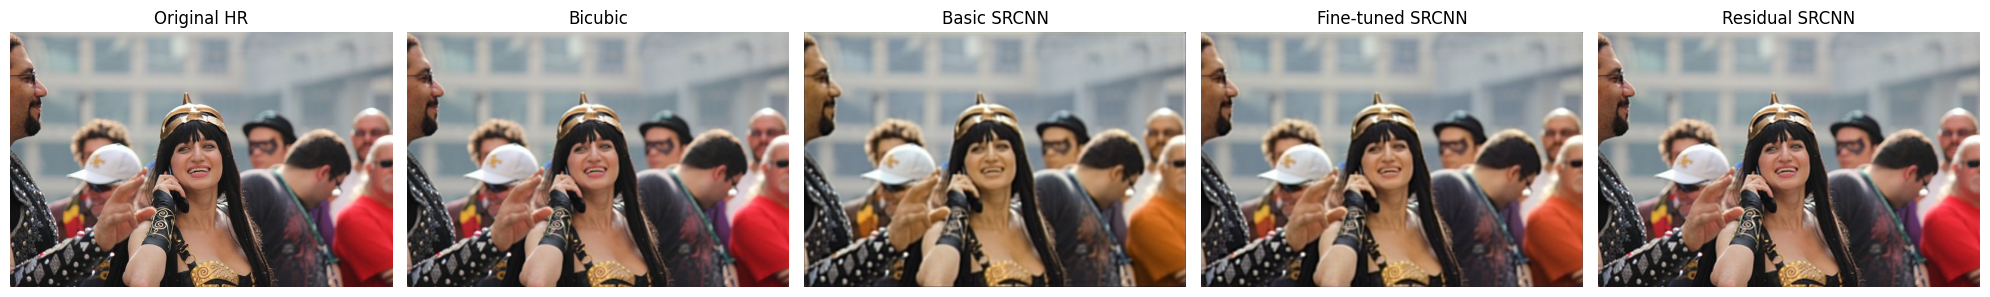

In [7]:
import os
import numpy as np
import torch
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

# 1. Device and folders
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

hr_dir = "/content/external_test/HR"
lr_dir = "/content/external_test/LR"
output_dir = "/content/external_test/outputs"

os.makedirs(output_dir, exist_ok=True)

# 2. Check all model weights
model_paths = {
    "Basic SRCNN": "/content/srcnn_model.pth",
    "Fine-tuned SRCNN": "/content/srcnn_model_finetuned.pth",
    "Residual SRCNN": "/content/residual_srcnn.pth"
}

for name, path in model_paths.items():
    if not os.path.exists(path):
        raise FileNotFoundError(f"Missing model weight: {path}")

# 3. Define SRCNN architecture (same as training)
class SRCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=9, padding=4),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 32, kernel_size=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 3, kernel_size=5, padding=2)
        )

    def forward(self, x):
        return self.network(x)

# 4. Define Residual SRCNN (same as training)
class ResidualSRCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=9, padding=4),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 32, kernel_size=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 3, kernel_size=5, padding=2)
        )
        nn.init.zeros_(self.features[-1].weight)
        nn.init.zeros_(self.features[-1].bias)

    def forward(self, x):
        return x + self.features(x)

# 5. Load all trained models
basic_model = SRCNN().to(device)
basic_model.load_state_dict(
    torch.load(model_paths["Basic SRCNN"], map_location=device)
)
basic_model.eval()

finetuned_model = SRCNN().to(device)
finetuned_model.load_state_dict(
    torch.load(model_paths["Fine-tuned SRCNN"], map_location=device)
)
finetuned_model.eval()

residual_model = ResidualSRCNN().to(device)
residual_model.load_state_dict(
    torch.load(model_paths["Residual SRCNN"], map_location=device)
)
residual_model.eval()

print("All three models loaded successfully!")
print("Testing device:", device)

# 6. Evaluate on the 10 new images
results = {
    "Bicubic": {"PSNR": [], "SSIM": []},
    "Basic SRCNN": {"PSNR": [], "SSIM": []},
    "Fine-tuned SRCNN": {"PSNR": [], "SSIM": []},
    "Residual SRCNN": {"PSNR": [], "SSIM": []}
}

hr_files = sorted([
    p for p in Path(hr_dir).iterdir()
    if p.suffix.lower() in (".jpg", ".jpeg", ".png", ".bmp", ".webp")
])

if len(hr_files) != 10:
    raise ValueError(f"Expected 10 HR images, found {len(hr_files)}")

def calculate_metrics(hr, prediction):
    psnr = peak_signal_noise_ratio(hr, prediction, data_range=255)
    ssim = structural_similarity(
        hr, prediction, channel_axis=2, data_range=255
    )
    return psnr, ssim

with torch.inference_mode():
    for index, hr_path in enumerate(hr_files, start=1):

        hr = np.array(
            Image.open(hr_path).convert("RGB")
        )

        lr_path = os.path.join(lr_dir, hr_path.stem + ".png")

        if not os.path.exists(lr_path):
            raise FileNotFoundError(f"Missing Bicubic input: {lr_path}")

        bicubic = np.array(
            Image.open(lr_path).convert("RGB")
        )

        if hr.shape != bicubic.shape:
            raise ValueError(f"Image dimension mismatch: {hr_path.name}")

        input_tensor = torch.from_numpy(
            bicubic.astype(np.float32) / 255.0
        ).permute(2, 0, 1).unsqueeze(0).to(device)

        # Generate predictions
        basic_pred = basic_model(input_tensor).clamp(0, 1)
        fine_pred = finetuned_model(input_tensor).clamp(0, 1)
        residual_pred = residual_model(input_tensor).clamp(0, 1)

        predictions = {
            "Basic SRCNN": basic_pred,
            "Fine-tuned SRCNN": fine_pred,
            "Residual SRCNN": residual_pred
        }

        # Bicubic metrics
        psnr, ssim = calculate_metrics(hr, bicubic)
        results["Bicubic"]["PSNR"].append(psnr)
        results["Bicubic"]["SSIM"].append(ssim)

        # Model metrics and save output images
        for model_name, prediction in predictions.items():

            pred = prediction.squeeze(0).cpu()
            pred = pred.permute(1, 2, 0).numpy()
            pred = (pred * 255).round().astype(np.uint8)

            psnr, ssim = calculate_metrics(hr, pred)

            results[model_name]["PSNR"].append(psnr)
            results[model_name]["SSIM"].append(ssim)

            model_folder = os.path.join(output_dir, model_name.replace(" ", "_"))
            os.makedirs(model_folder, exist_ok=True)

            Image.fromarray(pred).save(
                os.path.join(model_folder, hr_path.stem + ".png")
            )

        print(f"Processed image {index}/10: {hr_path.name}")

# 7. Display average results
summary = []

for model_name, metrics in results.items():
    summary.append({
        "Model": model_name,
        "Average PSNR (dB)": np.mean(metrics["PSNR"]),
        "Average SSIM": np.mean(metrics["SSIM"])
    })

results_df = pd.DataFrame(summary)

print("\n===== INDEPENDENT TEST RESULTS (10 NEW IMAGES) =====")
display(results_df.round(4))

print("\nAll prediction images saved in:", output_dir)

# 8. Display one example comparison
first_name = hr_files[0].stem

images_to_show = [
    ("Original HR", np.array(Image.open(hr_files[0]).convert("RGB"))),
    ("Bicubic", np.array(Image.open(os.path.join(lr_dir, first_name + ".png")).convert("RGB"))),
    ("Basic SRCNN", np.array(Image.open(os.path.join(output_dir, "Basic_SRCNN", first_name + ".png")))),
    ("Fine-tuned SRCNN", np.array(Image.open(os.path.join(output_dir, "Fine-tuned_SRCNN", first_name + ".png")))),
    ("Residual SRCNN", np.array(Image.open(os.path.join(output_dir, "Residual_SRCNN", first_name + ".png"))))
]

plt.figure(figsize=(20, 5))

for i, (title, image) in enumerate(images_to_show):
    plt.subplot(1, 5, i + 1)
    plt.imshow(image)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [11]:
import os

print("===== DATASET FOLDERS =====")
for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in ["_pycache_", ".config"]]

    if "High res" in dirs or "Low res" in dirs:
        print("Dataset location:", root)
        print("Folders:", dirs)

print("\n===== MODEL WEIGHTS =====")
for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.endswith(".pth"):
            print(os.path.join(root, file))

===== DATASET FOLDERS =====
Dataset location: /content/Dataset_1
Folders: ['Low res', 'High res']

===== MODEL WEIGHTS =====
/content/residual_srcnn.pth
/content/srcnn_model_finetuned.pth
/content/srcnn_model.pth
/content/model_weights/residual_srcnn.pth
/content/model_weights/srcnn_model_finetuned.pth
/content/model_weights/srcnn_model.pth


In [12]:
import os
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
from PIL import Image
from pathlib import Path
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from torchvision.transforms.functional import to_tensor
from tqdm.auto import tqdm

# 1. Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Testing device:", device)

# 2. Model architectures
class SRCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(3, 64, 9, padding=4),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 32, 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 3, 5, padding=2)
        )

    def forward(self, x):
        return self.network(x)


class ResidualSRCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, 9, padding=4),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 32, 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 3, 5, padding=2)
        )
        nn.init.zeros_(self.features[-1].weight)
        nn.init.zeros_(self.features[-1].bias)

    def forward(self, x):
        return x + self.features(x)


# 3. Load models
basic_model = SRCNN().to(device)
fine_model = SRCNN().to(device)
residual_model = ResidualSRCNN().to(device)

basic_model.load_state_dict(torch.load(
    "/content/srcnn_model.pth", map_location=device, weights_only=True
))
fine_model.load_state_dict(torch.load(
    "/content/srcnn_model_finetuned.pth", map_location=device, weights_only=True
))
residual_model.load_state_dict(torch.load(
    "/content/residual_srcnn.pth", map_location=device, weights_only=True
))

for model in [basic_model, fine_model, residual_model]:
    model.eval()

print("All three models loaded successfully!")

# 4. Dataset paths
hr_dir = Path("/content/Dataset_1/High res")
output_root = Path("/content/existing_50_evaluation")

for folder in ["Bicubic", "Basic_SRCNN", "Fine-tuned_SRCNN", "Residual_SRCNN"]:
    (output_root / folder).mkdir(parents=True, exist_ok=True)

hr_files = sorted([
    p for p in hr_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

print("HR images found:", len(hr_files))

# 5. Evaluation
rows = []

def calculate_metrics(reference, prediction):
    reference = np.clip(reference, 0, 1)
    prediction = np.clip(prediction, 0, 1)

    psnr = peak_signal_noise_ratio(
        reference, prediction, data_range=1.0
    )
    ssim = structural_similarity(
        reference, prediction, channel_axis=2, data_range=1.0
    )
    return psnr, ssim

with torch.inference_mode():
    for index, hr_path in enumerate(tqdm(hr_files), 1):

        hr_image = Image.open(hr_path).convert("RGB")
        width, height = hr_image.size

        # Bicubic downsample 2x and upsample
        lr_small = hr_image.resize(
            (max(1, width // 2), max(1, height // 2)),
            Image.Resampling.BICUBIC
        )
        bicubic_image = lr_small.resize(
            (width, height), Image.Resampling.BICUBIC
        )

        hr_array = np.asarray(hr_image, dtype=np.float32) / 255.0
        bicubic_array = np.asarray(bicubic_image, dtype=np.float32) / 255.0

        input_tensor = to_tensor(bicubic_image).unsqueeze(0).to(device)

        basic_output = basic_model(input_tensor).clamp(0, 1)
        fine_output = fine_model(input_tensor).clamp(0, 1)
        residual_output = residual_model(input_tensor).clamp(0, 1)

        outputs = {
            "Bicubic": bicubic_array,
            "Basic SRCNN": basic_output.squeeze(0).cpu().permute(1,2,0).numpy(),
            "Fine-tuned SRCNN": fine_output.squeeze(0).cpu().permute(1,2,0).numpy(),
            "Residual SRCNN": residual_output.squeeze(0).cpu().permute(1,2,0).numpy()
        }

        for model_name, prediction in outputs.items():
            psnr, ssim = calculate_metrics(hr_array, prediction)

            rows.append({
                "Image": hr_path.name,
                "Model": model_name,
                "PSNR (dB)": psnr,
                "SSIM": ssim
            })

            save_folder = {
                "Bicubic": "Bicubic",
                "Basic SRCNN": "Basic_SRCNN",
                "Fine-tuned SRCNN": "Fine-tuned_SRCNN",
                "Residual SRCNN": "Residual_SRCNN"
            }[model_name]

            save_image = Image.fromarray(
                (np.clip(prediction, 0, 1) * 255).astype(np.uint8)
            )
            save_image.save(output_root / save_folder / f"{hr_path.stem}.png")

        print(f"Processed {index}/{len(hr_files)}: {hr_path.name}")

# 6. Save individual results
existing_results_df = pd.DataFrame(rows)
existing_results_df.to_csv(
    "/content/existing_50_individual_results.csv", index=False
)

# 7. Average comparison table
existing_average_df = (
    existing_results_df.groupby("Model")[["PSNR (dB)", "SSIM"]]
    .mean().reset_index()
)

print("\n===== EXISTING 50 IMAGES: AVERAGE RESULTS =====")
display(existing_average_df.round(4))

print("\nIndividual results saved successfully!")
print("Prediction images saved in:", output_root)

Testing device: cuda
All three models loaded successfully!
HR images found: 50


  0%|          | 0/50 [00:00<?, ?it/s]

Processed 1/50: 000000000139.jpg
Processed 2/50: 000000000285.jpg
Processed 3/50: 000000000632.jpg
Processed 4/50: 000000000724.jpg
Processed 5/50: 000000000776.jpg
Processed 6/50: 000000000785.jpg
Processed 7/50: 000000000802.jpg
Processed 8/50: 000000000872.jpg
Processed 9/50: 000000000885.jpg
Processed 10/50: 000000001000.jpg
Processed 11/50: 000000001268.jpg
Processed 12/50: 000000001296.jpg
Processed 13/50: 000000001353.jpg
Processed 14/50: 000000001425.jpg
Processed 15/50: 000000001490.jpg
Processed 16/50: 000000001503.jpg
Processed 17/50: 000000001532.jpg
Processed 18/50: 000000001584.jpg
Processed 19/50: 000000001675.jpg
Processed 20/50: 000000001761.jpg
Processed 21/50: 000000001818.jpg
Processed 22/50: 000000001993.jpg
Processed 23/50: 000000002006.jpg
Processed 24/50: 000000002149.jpg
Processed 25/50: 000000002153.jpg
Processed 26/50: 000000002157.jpg
Processed 27/50: 000000002261.jpg
Processed 28/50: 000000002299.jpg
Processed 29/50: 000000002431.jpg
Processed 30/50: 000000

,Model,PSNR (dB),SSIM
0,Basic SRCNN,24.4948,0.7508
1,Bicubic,28.0079,0.8421
2,Fine-tuned SRCNN,25.8316,0.7840
3,Residual SRCNN,28.4951,0.8573



Individual results saved successfully!
Prediction images saved in: /content/existing_50_evaluation


In [13]:
import os

check_paths = [
    "/content/external_test/HR",
    "/content/external_test/LR",
    "/content/external_test/outputs/Basic_SRCNN",
    "/content/external_test/outputs/Fine-tuned_SRCNN",
    "/content/external_test/outputs/Residual_SRCNN",
    "/content/existing_50_evaluation",
    "/content/existing_50_individual_results.csv"
]

print("===== FILE CHECK =====")

for path in check_paths:
    if os.path.isfile(path):
        print("FOUND:", path)
    elif os.path.isdir(path):
        files = os.listdir(path)
        print(f"FOUND: {path} | Files: {len(files)}")
    else:
        print("MISSING:", path)

===== FILE CHECK =====
FOUND: /content/external_test/HR | Files: 10
FOUND: /content/external_test/LR | Files: 10
FOUND: /content/external_test/outputs/Basic_SRCNN | Files: 10
FOUND: /content/external_test/outputs/Fine-tuned_SRCNN | Files: 10
FOUND: /content/external_test/outputs/Residual_SRCNN | Files: 10
FOUND: /content/existing_50_evaluation | Files: 4
FOUND: /content/existing_50_individual_results.csv


===== FINAL AVERAGE COMPARISON TABLE =====


,Evaluation,Model,PSNR (dB),SSIM
0,Existing 50 Images,Bicubic,28.0079,0.8421
1,New 10 Images,Bicubic,25.8334,0.7811
2,Existing 50 Images,Basic SRCNN,24.4948,0.7508
3,New 10 Images,Basic SRCNN,23.4407,0.6820
4,Existing 50 Images,Fine-tuned SRCNN,25.8316,0.7840
5,New 10 Images,Fine-tuned SRCNN,24.3758,0.7169
6,Existing 50 Images,Residual SRCNN,28.4951,0.8573
7,New 10 Images,Residual SRCNN,26.2087,0.8038


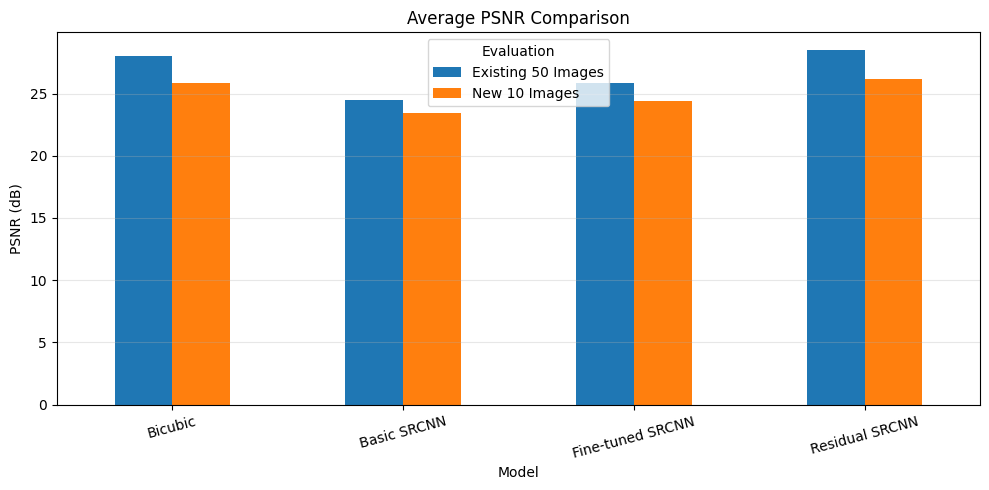

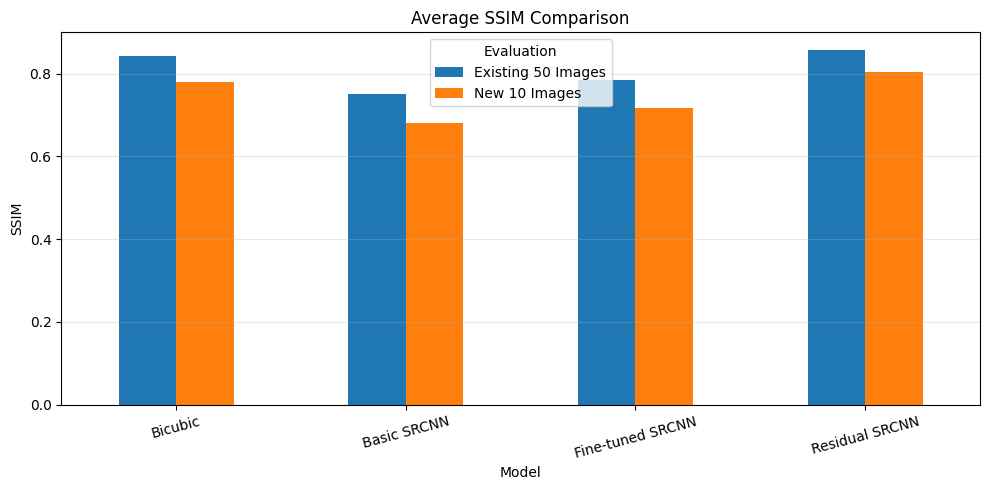


Comparison table and both graphs saved successfully!


In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Output folder
final_dir = "/content/Final_Project_Results"
os.makedirs(final_dir, exist_ok=True)
os.makedirs(final_dir + "/graphs", exist_ok=True)

# 1. Existing 50 images average
existing_df = pd.read_csv(
    "/content/existing_50_individual_results.csv"
)

existing_avg = (
    existing_df.groupby("Model")[["PSNR (dB)", "SSIM"]]
    .mean()
)

# 2. New 10 images results (previous successful evaluation)
new_results = {
    "Bicubic": [25.8334, 0.7811],
    "Basic SRCNN": [23.4407, 0.6820],
    "Fine-tuned SRCNN": [24.3758, 0.7169],
    "Residual SRCNN": [26.2087, 0.8038]
}

new_avg = pd.DataFrame(
    new_results,
    index=["PSNR (dB)", "SSIM"]
).T

# 3. Combine comparison table
models = [
    "Bicubic",
    "Basic SRCNN",
    "Fine-tuned SRCNN",
    "Residual SRCNN"
]

comparison_rows = []

for model in models:
    comparison_rows.append({
        "Evaluation": "Existing 50 Images",
        "Model": model,
        "PSNR (dB)": existing_avg.loc[model, "PSNR (dB)"],
        "SSIM": existing_avg.loc[model, "SSIM"]
    })

    comparison_rows.append({
        "Evaluation": "New 10 Images",
        "Model": model,
        "PSNR (dB)": new_avg.loc[model, "PSNR (dB)"],
        "SSIM": new_avg.loc[model, "SSIM"]
    })

comparison_df = pd.DataFrame(comparison_rows)

comparison_df.to_csv(
    final_dir + "/average_comparison_table.csv",
    index=False
)

print("===== FINAL AVERAGE COMPARISON TABLE =====")
display(comparison_df.round(4))

# 4. PSNR Graph
psnr_pivot = comparison_df.pivot(
    index="Model", columns="Evaluation", values="PSNR (dB)"
).reindex(models)

ax = psnr_pivot.plot(kind="bar", figsize=(10, 5))
ax.set_title("Average PSNR Comparison")
ax.set_ylabel("PSNR (dB)")
ax.set_xlabel("Model")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(final_dir + "/graphs/PSNR_comparison.png", dpi=300)
plt.show()

# 5. SSIM Graph
ssim_pivot = comparison_df.pivot(
    index="Model", columns="Evaluation", values="SSIM"
).reindex(models)

ax = ssim_pivot.plot(kind="bar", figsize=(10, 5))
ax.set_title("Average SSIM Comparison")
ax.set_ylabel("SSIM")
ax.set_xlabel("Model")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(final_dir + "/graphs/SSIM_comparison.png", dpi=300)
plt.show()

print("\nComparison table and both graphs saved successfully!")

In [16]:
from PIL import Image
import matplotlib.pyplot as plt
import os
from pathlib import Path

final_dir = "/content/Final_Project_Results"
visual_dir = final_dir + "/visual_comparison"
os.makedirs(visual_dir, exist_ok=True)

# Select 5 existing images and 5 new images
existing_hr = Path("/content/Dataset_1/High res")
new_hr = Path("/content/external_test/HR")

existing_samples = sorted([
    p for p in existing_hr.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])[:5]

new_samples = sorted([
    p for p in new_hr.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])[:5]

def create_comparison(hr_path, source, output_name):
    if source == "existing":
        base = "/content/existing_50_evaluation"
    else:
        base = "/content/external_test/outputs"

    name = hr_path.stem

    paths = [
        hr_path,
        Path(base) / "Bicubic" / f"{name}.png",
        Path(base) / "Basic_SRCNN" / f"{name}.png",
        Path(base) / "Fine-tuned_SRCNN" / f"{name}.png",
        Path(base) / "Residual_SRCNN" / f"{name}.png"
    ]

    titles = [
        "Original HR",
        "Bicubic",
        "Basic SRCNN",
        "Fine-tuned SRCNN",
        "Residual SRCNN"
    ]

    fig, axes = plt.subplots(1, 5, figsize=(20, 5))

    for ax, path, title in zip(axes, paths, titles):
        if not path.exists():
            ax.set_title(title + "\nMissing")
            ax.axis("off")
            continue

        image = Image.open(path).convert("RGB")
        ax.imshow(image)
        ax.set_title(title)
        ax.axis("off")

    plt.suptitle(f"{source.title()} Image Comparison: {name}")
    plt.tight_layout()

    save_path = os.path.join(visual_dir, output_name)
    plt.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()

# Existing 50 images: 5 samples
for i, path in enumerate(existing_samples, 1):
    create_comparison(
        path, "existing", f"Existing_{i}_{path.stem}.png"
    )

# New 10 images: 5 samples
for i, path in enumerate(new_samples, 1):
    create_comparison(
        path, "new", f"New_{i}_{path.stem}.png"
    )

print("\nVisual comparisons saved:", visual_dir)
print("Total comparison images:", len(os.listdir(visual_dir)))

Output hidden; open in https://colab.research.google.com to view.

In [17]:
from PIL import Image
import matplotlib.pyplot as plt
import os
from pathlib import Path

visual_dir = "/content/Final_Project_Results/visual_comparison"
os.makedirs(visual_dir, exist_ok=True)

new_hr_dir = Path("/content/external_test/HR")
new_lr_dir = Path("/content/external_test/LR")
output_dir = Path("/content/external_test/outputs")

new_samples = sorted([
    p for p in new_hr_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])[:5]

def create_new_comparison(hr_path):
    name = hr_path.stem

    paths = [
        hr_path,
        new_lr_dir / f"{name}.png",
        output_dir / "Basic_SRCNN" / f"{name}.png",
        output_dir / "Fine-tuned_SRCNN" / f"{name}.png",
        output_dir / "Residual_SRCNN" / f"{name}.png"
    ]

    titles = [
        "Original HR",
        "Bicubic",
        "Basic SRCNN",
        "Fine-tuned SRCNN",
        "Residual SRCNN"
    ]

    fig, axes = plt.subplots(1, 5, figsize=(20, 5))

    for ax, path, title in zip(axes, paths, titles):
        if path.exists():
            img = Image.open(path).convert("RGB")
            ax.imshow(img)
            ax.set_title(title)
        else:
            ax.set_title(title + "\nMissing")
            print("Missing file:", path)

        ax.axis("off")

    plt.suptitle(f"New Independent Test: {name}")
    plt.tight_layout()

    save_path = os.path.join(
        visual_dir, f"New_{name}_Comparison.png"
    )

    plt.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()

for path in new_samples:
    create_new_comparison(path)

print("\nNew image comparisons saved successfully!")

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import os
from pathlib import Path

final_dir = "/content/Final_Project_Results"
visual_dir = final_dir + "/visual_comparison"
os.makedirs(visual_dir, exist_ok=True)

existing_hr_dir = Path("/content/Dataset_1/High res")
existing_output = Path("/content/existing_50_evaluation")

new_hr_dir = Path("/content/external_test/HR")
new_output = Path("/content/external_test/outputs")
new_lr_dir = Path("/content/external_test/LR")

titles = [
    "Original HR",
    "Bicubic",
    "Basic SRCNN",
    "Fine-tuned SRCNN",
    "Residual SRCNN"
]

def create_comparison(hr_path, dataset_type, number):
    name = hr_path.stem

    if dataset_type == "Existing":
        paths = [
            hr_path,
            existing_output / "Bicubic" / f"{name}.png",
            existing_output / "Basic_SRCNN" / f"{name}.png",
            existing_output / "Fine-tuned_SRCNN" / f"{name}.png",
            existing_output / "Residual_SRCNN" / f"{name}.png"
        ]
    else:
        paths = [
            hr_path,
            new_lr_dir / f"{name}.png",
            new_output / "Basic_SRCNN" / f"{name}.png",
            new_output / "Fine-tuned_SRCNN" / f"{name}.png",
            new_output / "Residual_SRCNN" / f"{name}.png"
        ]

    missing = [str(p) for p in paths if not p.exists()]
    if missing:
        print(f"Skipping {dataset_type} {name}. Missing files:")
        for p in missing:
            print(p)
        return False

    fig, axes = plt.subplots(1, 5, figsize=(22, 5))

    for ax, path, title in zip(axes, paths, titles):
        img = Image.open(path).convert("RGB")
        ax.imshow(img)
        ax.set_title(title)
        ax.axis("off")

    fig.suptitle(
        f"{dataset_type} Image {number}: {name}",
        fontsize=14
    )
    plt.tight_layout()

    filename = f"{dataset_type}_{number}_{name}_Comparison.png"
    plt.savefig(
        os.path.join(visual_dir, filename),
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

    return True


# Remove old comparison images so the folder contains only final 10
for file in os.listdir(visual_dir):
    if file.endswith(".png"):
        os.remove(os.path.join(visual_dir, file))

existing_samples = sorted([
    p for p in existing_hr_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])[:5]

new_samples = sorted([
    p for p in new_hr_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])[:5]

success_count = 0

for i, path in enumerate(existing_samples, 1):
    success_count += create_comparison(path, "Existing", i)

for i, path in enumerate(new_samples, 1):
    success_count += create_comparison(path, "New", i)

print("\n===== FINAL VISUAL COMPARISON =====")
print("Successfully created:", success_count, "out of 10")
print("Saved folder:", visual_dir)

assert success_count == 10, (
    "Some images are missing. Check the missing file paths printed above."
)